# Three computer-vision tasks on one image

**Ernestas Lazurkevicius - PRIf-24/2, VilniusTech**

An adaptation of the lecturer's `cnn_One_Image.ipynb` (Algirdas Laukaitis).

## What the original notebook does

Where the transfer-learning notebook *trains* a model, this one **trains nothing**. It
loads models that are already trained and shows what three different kinds of computer
vision produce from the same photograph. The contrast between them is the lesson:

| Chapter | Task | Question it answers | Output |
|---|---|---|---|
| 1 | Image **classification** | "What is this a picture of?" | one label for the whole image |
| 2 | Object **detection** | "What objects are in it, and where?" | boxes with labels and scores |
| 3 | Image **segmentation** | "Which pixels belong to what?" | a mask per class, pixel by pixel |

Chapter 1 runs **two** classifiers on the same image - one trained on ImageNet-21k
(21,843 classes) and one further tuned on ImageNet-1k (1,000 classes) - so their answers
can be compared directly. It then crops a piece out of the photo and runs them again,
which usually changes the answer completely: a classifier returns one label for whatever
fills the frame, so changing the frame changes the subject.

## What this notebook changes

The three chapters, the models and the method are unchanged. What changes is **which
image goes in**, plus repairs to the image-loading code - which is exactly the part that
breaks once you stop using a curated list of JPEGs and start using your own photos.

| | Original | This notebook |
|---|---|---|
| Image source | dropdown of 15 fixed Wikimedia URLs | your upload, any URL, or a dataset sample |
| Grayscale images | crashes | converted to RGB |
| PNG / screenshots with transparency | wrong channel count | converted to RGB |
| Phone photos | sideways | EXIF rotation applied |
| Segmentation masks shown | four hard-coded indices | the most active classes, found automatically |

Every deviation is marked with a **`# CHANGE:`** comment.

> **Status: not yet executed.** This notebook could not be run before delivery - the
> environment it was written in cannot reach TF Hub or the image hosts. Every cell has
> been syntax-checked and reviewed, but the outputs appear only after the first Colab run.

---
## Setup

In [1]:
# NOTE: importlib_resources is listed explicitly on purpose.
# tensorflow-datasets does not declare it as a dependency, but
# tensorflow_datasets/core/dataset_builder.py imports it. On Python 3.13 that
# surfaces as "ModuleNotFoundError: No module named 'importlib_resources'" the
# first time tfds.load() runs - not when tensorflow_datasets is imported, which
# is why the error appears further down the notebook than you would expect.
%pip install -q tensorflow_hub tensorflow-datasets importlib_resources

In [2]:
# CHANGE: tempfile and urllib added. The original's helper block calls
# tempfile.mkstemp() and urlopen() but never imports either - that function raises
# NameError if anything calls it. See "Defects in the original" at the end.
import json
import math
import tempfile
from io import BytesIO
from urllib.request import urlopen

import numpy as np
import requests
import tensorflow as tf
import tensorflow_hub as hub
import matplotlib.pyplot as plt

from PIL import Image, ImageColor, ImageDraw, ImageFont, ImageOps
from IPython.display import HTML, display

print("TensorFlow", tf.__version__)

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


TensorFlow 2.21.0


## Loading an image, properly

This is the part that had to be rewritten rather than adapted, so it is worth explaining
before the models appear.

The original's loader works on its fifteen curated Wikimedia JPEGs and breaks on most
other input:

**It crashes on grayscale images.** `preprocess_image` immediately does
`tf.reshape(image, [1, image.shape[0], image.shape[1], image.shape[2]])`. A grayscale
photo becomes a 2-D NumPy array, so `image.shape[2]` raises `IndexError` before anything
else runs. The original *does* contain a grayscale guard -
`if len(img.shape) == 3: img = tf.stack([img, img, img], axis=-1)` - but it sits in
`load_image`, which runs **after** `preprocess_image` has already crashed. It is
unreachable, and if it ever did run it would produce a 5-D tensor, because by that point
the image already has a batch dimension.

**It mishandles transparency.** A PNG or a screenshot loads with four channels (RGBA).
The models expect three. Nothing checks.

**It ignores EXIF rotation.** Phone cameras store the image unrotated plus an orientation
flag. Ignore the flag and portrait photos arrive sideways.

All three disappear with two lines: `ImageOps.exif_transpose()` to apply the rotation, and
`.convert("RGB")`, which turns grayscale, palette and RGBA images into plain three-channel
RGB.

### One thing the original gets right

`tf.image.convert_image_dtype(..., tf.float32)` already rescales `uint8` pixels to the
`[0, 1]` range, which is what these TF-Hub models expect. The original then adds
`if tf.reduce_max(img) > 1.0: img = img / 255.` - which can never fire, since the values
are already at most 1.0. Harmless, but it suggests uncertainty about what the conversion
did. The version below converts once and says so.

In [3]:
# CHANGE: rewritten loader. Handles grayscale, RGBA, palette images and EXIF
# rotation; converts to [0, 1] float exactly once.

def pil_from_any(source):
    """Open a local path, an http(s) URL or raw bytes as an RGB PIL image."""
    if isinstance(source, (bytes, bytearray)):
        image = Image.open(BytesIO(source))
    elif isinstance(source, str) and source.startswith(("http://", "https://")):
        response = requests.get(source, headers={"User-agent": "Mozilla/5.0"}, timeout=60)
        response.raise_for_status()
        image = Image.open(BytesIO(response.content))
    else:
        image = Image.open(source)

    image = ImageOps.exif_transpose(image)   # phone photos arrive rotated
    return image.convert("RGB")              # grayscale, palette and RGBA all become RGB


def to_batched_tensor(pil_image):
    """RGB PIL image -> float32 tensor [1, height, width, 3] with values in [0, 1]."""
    array = np.array(pil_image)                                  # always (h, w, 3) now
    tensor = tf.image.convert_image_dtype(array, tf.float32)     # uint8 -> [0, 1] float
    return tensor[tf.newaxis, ...]                               # add the batch axis


def fit_for_model(batched, size):
    """Resize to the square the model wants, padding rather than distorting."""
    return tf.image.resize_with_pad(batched, size, size)


def show_image(batched, title=""):
    plt.figure(figsize=(7, 7))
    plt.imshow(np.clip(batched[0].numpy(), 0, 1))
    plt.axis("off")
    plt.title(title)
    plt.show()

## Choose the image

Three ways in. `IMAGE_SOURCE` picks one.

* **`"sample"`** - a photo from the `tf_flowers` dataset, the same data the
  transfer-learning notebook trains on. Downloads itself, so the notebook runs end to end
  with no input.
* **`"upload"`** - your own file, through Colab's upload button.
* **`"url"`** - any public image address.

A note on what to pick: a single flower is a clean subject for **classification**, but
Chapters 2 and 3 have little to find in it. Object detection and segmentation show far
more on a scene with several things in it - a street, a room, a group of people. If you
upload one photo, make it a busy one.

In [4]:
# CHANGE: three selectable sources, replacing the fixed Wikimedia dropdown.
IMAGE_SOURCE = "sample"  # @param ["sample", "upload", "url"]
IMAGE_URL = ""           # @param {type:"string"}

if IMAGE_SOURCE == "upload":
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("No file was uploaded.")
    first_name = list(uploaded.keys())[0]
    pil_image = pil_from_any(uploaded[first_name])
    source_description = f"uploaded file: {first_name}"

elif IMAGE_SOURCE == "url":
    if not IMAGE_URL:
        raise ValueError("Set IMAGE_URL, or switch IMAGE_SOURCE to 'sample'.")
    pil_image = pil_from_any(IMAGE_URL)
    source_description = f"url: {IMAGE_URL}"

else:
    # NOTE: this downloads the whole tf_flowers dataset (~220 MB) to take one
    # image. "upload" or "url" above is much faster if you just want to try the
    # notebook. The failure below is caught because tensorflow-datasets raises a
    # missing-dependency error inside load(), not at import.
    try:
        import tensorflow_datasets as tfds
        sample_ds = tfds.load("tf_flowers", split="train[:1]", as_supervised=True)
        sample_image, sample_label = next(iter(sample_ds))
    except ModuleNotFoundError as error:
        raise ModuleNotFoundError(
            f"tensorflow-datasets could not load the sample: {error}\n\n"
            "Fix: re-run the install cell at the top of this notebook, then\n"
            "Runtime -> Restart session, then Runtime -> Run all.\n\n"
            "Or avoid it entirely: set IMAGE_SOURCE = 'upload' or 'url' above.\n"
            "Neither needs tensorflow-datasets, and both are faster."
        ) from error

    pil_image = Image.fromarray(sample_image.numpy()).convert("RGB")
    source_description = "tf_flowers sample"

print("Source :", source_description)
print("Size   :", pil_image.size)
print("Mode   :", pil_image.mode)

original_image = to_batched_tensor(pil_image)
print("Tensor :", original_image.shape)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.X9KSZT_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Source : tf_flowers sample
Size   : (500, 333)
Mode   : RGB
Tensor : (1, 333, 500, 3)


---
# Chapter 1. Image classification

Two classifiers, one image.

* **Model 1** was trained on **ImageNet-21k**: 21,843 classes, a very fine-grained
  vocabulary that includes specific species, buildings and objects.
* **Model 2** is the same architecture, further tuned on **ImageNet-1k**: 1,000 broad
  everyday classes.

Running both shows that "what the model knows" is decided by the label set it was trained
on, not by the architecture. The 21k model can name a specific flower species; the 1k
model has to pick the closest of its thousand options. Neither is more correct - they
answer different questions.

Both output **logits**, so `tf.nn.softmax` converts them to probabilities that sum to 1.

In [5]:
INPUT_SIZE = 384

classifier_21k = hub.load(
    "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_s/classification/2")
classifier_1k = hub.load(
    "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_ft1k_s/classification/2")

print("Both classifiers loaded.")

Both classifiers loaded.


In [6]:
labels_21k_path = tf.keras.utils.get_file(
    "imagenet21k_wordnet_lemmas.txt",
    "https://huggingface.co/spaces/TexR6/AttentionMaps/resolve/main/labels/"
    "imagenet21k_wordnet_lemmas.txt",
)
classes_21k = np.array(open(labels_21k_path).read().splitlines())

labels_1k_path = tf.keras.utils.get_file(
    "imagenet1k_wordnet_lemmas.txt",
    "https://storage.googleapis.com/download.tensorflow.org/data/ImageNetLabels.txt",
)
classes_1k = np.array(open(labels_1k_path).read().splitlines())[1:]   # drop 'background'

# Sanity check: label counts must match each model's output width, or every
# prediction would be reported under the wrong name.
probe = tf.zeros([1, INPUT_SIZE, INPUT_SIZE, 3])
print(len(classes_21k), classifier_21k(probe).shape)
print(len(classes_1k), classifier_1k(probe).shape)

522999/522999 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
10484/10484 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
21843 (1, 21843)
1000 (1, 1000)


In [7]:
# CHANGE: returns (label, probability) pairs instead of a preformatted string,
# so the results can be charted as well as printed.
def classify(batched_image, classifier, classes, top_n=4):
    probabilities = tf.nn.softmax(classifier(batched_image)).numpy()[0]
    top_indices = np.argsort(probabilities)[::-1][:top_n]
    return [(int(i), classes[i], float(probabilities[i])) for i in top_indices]


def show_classifications(batched_image, title=""):
    show_image(batched_image, title)

    for name, classifier, classes in [
        ("Model 1 - ImageNet-21k (21,843 classes)", classifier_21k, classes_21k),
        ("Model 2 - ImageNet-1k (1,000 classes)", classifier_1k, classes_1k),
    ]:
        print(name)
        for rank, (index, label, probability) in enumerate(
                classify(batched_image, classifier, classes), start=1):
            print(f"  {rank}) {index:6d}  {label:<45s} p = {probability:.4f}")
        print()

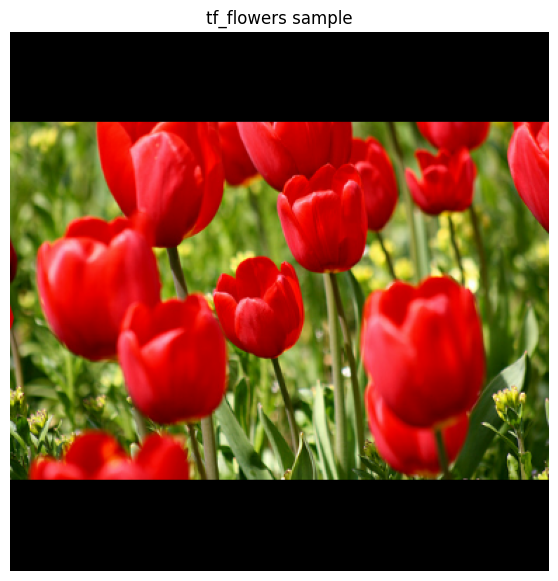

Model 1 - ImageNet-21k (21,843 classes)
  1)  19631  cottage_tulip                                 p = 0.1631
  2)  19632  Darwin_tulip                                  p = 0.1299
  3)  19538  Cape_tulip, Haemanthus_coccineus              p = 0.1052
  4)  17521  flower                                        p = 0.0713

Model 2 - ImageNet-1k (1,000 classes)
  1)    945  bell pepper                                   p = 0.0206
  2)    417  balloon                                       p = 0.0202
  3)    985  daisy                                         p = 0.0126
  4)    995  earthstar                                     p = 0.0110



In [8]:
image = fit_for_model(original_image, INPUT_SIZE)
show_classifications(image, source_description)

## Crop a piece out and classify again

The experiment that makes the limitation of classification visible. A classifier returns
**one** label for the whole frame. Change the frame and the subject changes with it - the
model has no way to say "there are several things here", which is precisely the gap
Chapter 2 fills.

Adjust the sliders to move the crop window around the photo.

Full image: 500 x 333
Crop: (150,66) to (500,333) = 350 x 267 pixels



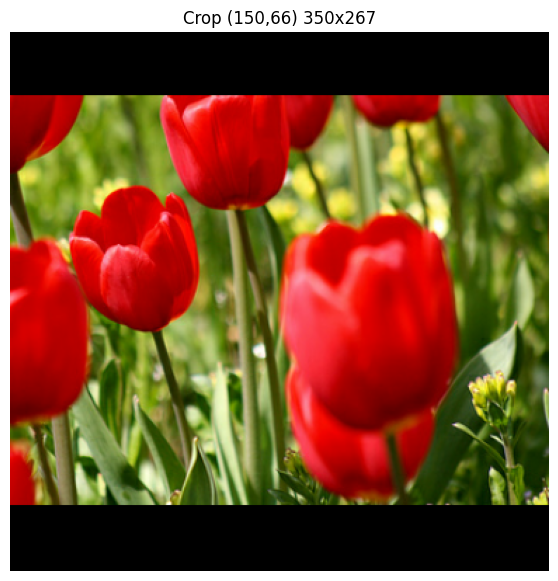

Model 1 - ImageNet-21k (21,843 classes)
  1)  19632  Darwin_tulip                                  p = 0.2160
  2)  19631  cottage_tulip                                 p = 0.1760
  3)  19538  Cape_tulip, Haemanthus_coccineus              p = 0.1218
  4)  19630  Tulipa_gesneriana                             p = 0.1011

Model 2 - ImageNet-1k (1,000 classes)
  1)    985  daisy                                         p = 0.0177
  2)    945  bell pepper                                   p = 0.0114
  3)    995  earthstar                                     p = 0.0109
  4)    417  balloon                                       p = 0.0091



In [9]:
# CHANGE: the crop is clamped to the image bounds. In the original, dragging the
# sliders far enough right or down produces a zero-width slice and the next cell fails
# inside the model with a confusing shape error.
x_percent = 30   # @param {type:"slider", min:0, max:100, step:1}
y_percent = 20   # @param {type:"slider", min:0, max:100, step:1}
cut_size_in_pixels = 500  # @param {type:"integer"}

height, width = int(original_image.shape[1]), int(original_image.shape[2])

x_start = min(int(width * x_percent / 100), max(width - 1, 0))
y_start = min(int(height * y_percent / 100), max(height - 1, 0))
x_end = min(x_start + cut_size_in_pixels, width)
y_end = min(y_start + cut_size_in_pixels, height)

image_cut = original_image[:, y_start:y_end, x_start:x_end, :]
image = fit_for_model(image_cut, INPUT_SIZE)

print(f"Full image: {width} x {height}")
print(f"Crop: ({x_start},{y_start}) to ({x_end},{y_end}) "
      f"= {x_end - x_start} x {y_end - y_start} pixels")
print()

show_classifications(image, f"Crop ({x_start},{y_start}) "
                            f"{x_end - x_start}x{y_end - y_start}")

---
# Chapter 2. Object detection

Classification answers "what is this?". Detection answers "**what things are here, and
where?**" - returning a box, a label and a confidence score for each object it finds.

The model is **SSD MobileNet V2** trained on **Open Images V4** (600 object classes).
SSD means *Single Shot Detector*: one forward pass produces all the boxes, which is what
makes it fast enough for video. MobileNet V2 is a deliberately small backbone built for
phones, so it trades some accuracy for speed.

Low-confidence boxes are filtered out by `min_score`. Set it too low and the image fills
with spurious boxes; too high and real objects are missed.

In [10]:
detector = hub.load(
    "https://tfhub.dev/google/openimages_v4/ssd/mobilenet_v2/1").signatures["default"]
print("Detector loaded.")

Detector loaded.


In [11]:
# Drawing helpers, unchanged in substance from the original.

def draw_bounding_box_on_image(image, ymin, xmin, ymax, xmax, color, font,
                               thickness=4, display_str_list=()):
    draw = ImageDraw.Draw(image)
    im_width, im_height = image.size
    (left, right, top_edge, bottom) = (xmin * im_width, xmax * im_width,
                                       ymin * im_height, ymax * im_height)
    draw.line([(left, top_edge), (left, bottom), (right, bottom),
               (right, top_edge), (left, top_edge)], width=thickness, fill=color)

    display_str_heights = [font.getbbox(ds)[3] for ds in display_str_list]
    total_display_str_height = (1 + 2 * 0.05) * sum(display_str_heights)

    text_bottom = top_edge if top_edge > total_display_str_height else (
        top_edge + total_display_str_height)

    for display_str in display_str_list[::-1]:
        bbox = font.getbbox(display_str)
        text_width, text_height = bbox[2], bbox[3]
        margin = np.ceil(0.05 * text_height)
        draw.rectangle([(left, text_bottom - text_height - 2 * margin),
                        (left + text_width, text_bottom)], fill=color)
        draw.text((left + margin, text_bottom - text_height - margin),
                  display_str, fill="black", font=font)
        text_bottom -= text_height - 2 * margin


def draw_boxes(image, boxes, class_names, scores, max_boxes=20, min_score=0.1):
    colors = list(ImageColor.colormap.values())
    try:
        font = ImageFont.truetype(
            "/usr/share/fonts/truetype/liberation/LiberationSansNarrow-Regular.ttf", 25)
    except IOError:
        font = ImageFont.load_default()

    for i in range(min(boxes.shape[0], max_boxes)):
        if scores[i] >= min_score:
            ymin, xmin, ymax, xmax = tuple(boxes[i])
            display_str = "{}: {}%".format(
                class_names[i].decode("ascii"), int(100 * scores[i]))
            color = colors[hash(class_names[i]) % len(colors)]
            image_pil = Image.fromarray(np.uint8(image)).convert("RGB")
            draw_bounding_box_on_image(image_pil, ymin, xmin, ymax, xmax,
                                       color, font, display_str_list=[display_str])
            np.copyto(image, np.array(image_pil))
    return image


def run_detector(batched_image, min_score=0.1, max_boxes=20):
    result = detector(batched_image)
    result = {key: value.numpy() for key, value in result.items()}

    kept = int((result["detection_scores"] >= min_score).sum())
    print(f"{len(result['detection_scores'])} candidate boxes, "
          f"{kept} above the {min_score} threshold.")

    canvas = tf.cast(batched_image[0] * 255, tf.uint8).numpy()
    drawn = draw_boxes(canvas, result["detection_boxes"],
                       result["detection_class_entities"],
                       result["detection_scores"],
                       max_boxes=max_boxes, min_score=min_score)

    plt.figure(figsize=(16, 12))
    plt.grid(False)
    plt.axis("off")
    plt.imshow(drawn)
    plt.show()
    return result

100 candidate boxes, 41 above the 0.1 threshold.


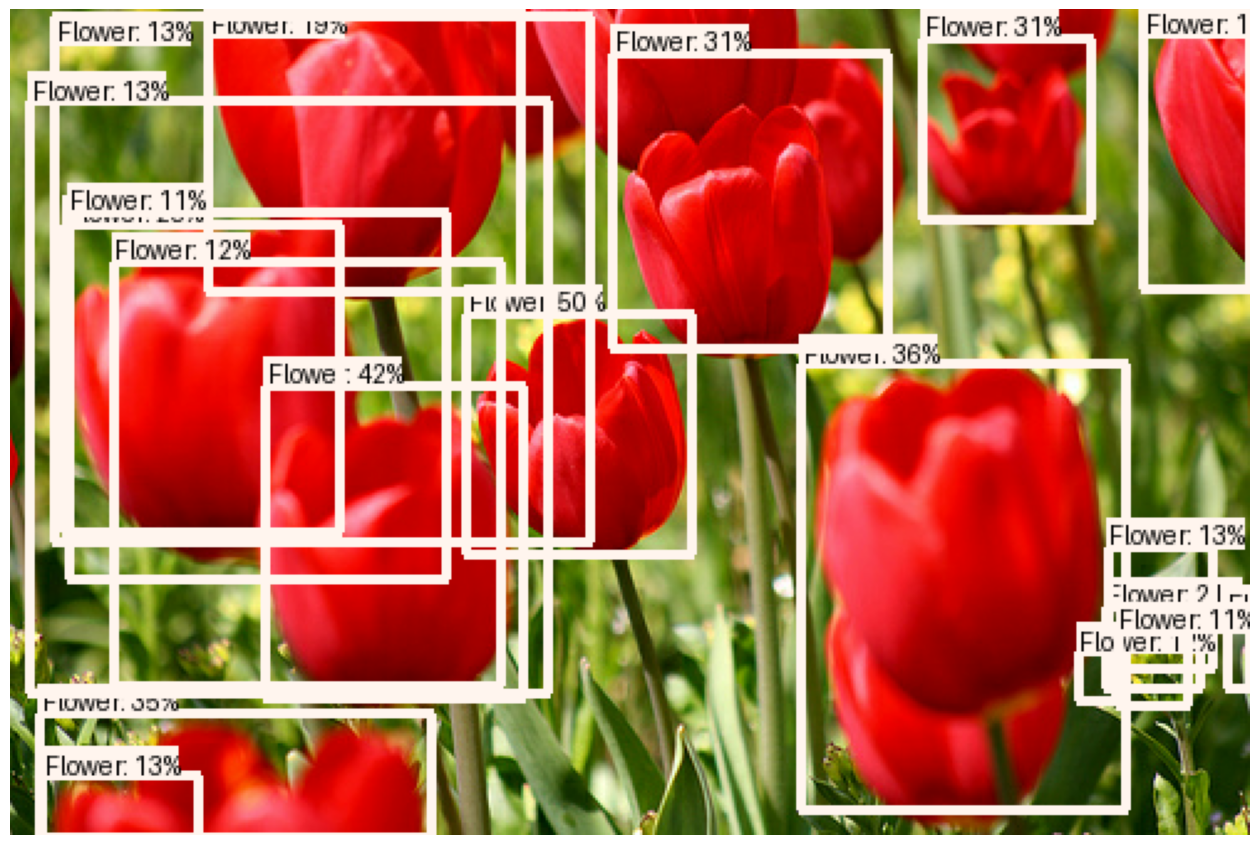

In [12]:
detector_output = run_detector(original_image, min_score=0.1)

In [13]:
# CHANGE (new cell): rank what was actually found, which the picture alone
# does not make readable once boxes overlap.
scores = detector_output["detection_scores"]
entities = detector_output["detection_class_entities"]

print("Highest-scoring detections:")
for score, entity in list(zip(scores, entities))[:10]:
    print(f"  {entity.decode('ascii'):<25s} {score:.3f}")

Highest-scoring detections:
  Rose                      0.605
  Flower                    0.502
  Flower                    0.424
  Flower                    0.369
  Flower                    0.354
  Flower                    0.319
  Flower                    0.319
  Flower                    0.258
  Flower                    0.219
  Flower                    0.190


100 candidate boxes, 11 above the 0.1 threshold.


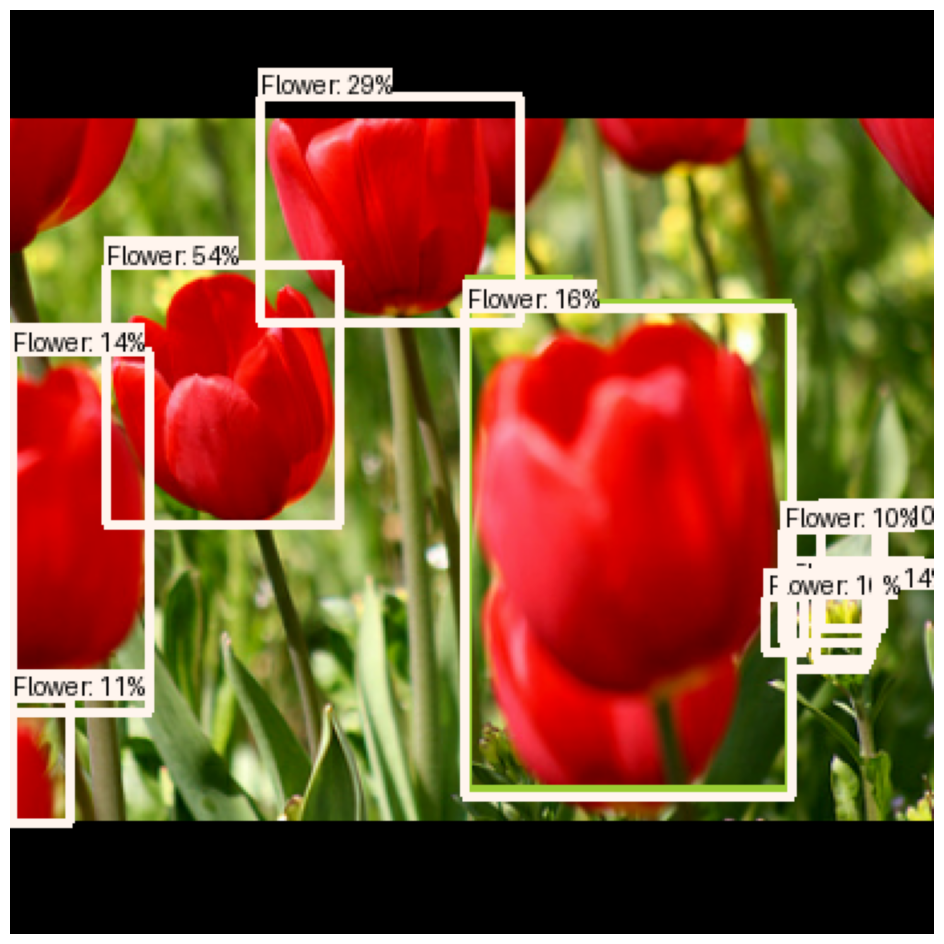

In [14]:
# The same detector on the crop. Detection is far less sensitive to framing than
# classification: objects still inside the crop keep their labels.
detector_output_cut = run_detector(image, min_score=0.1)

---
# Chapter 3. Image segmentation

The finest-grained of the three. Rather than one label for the image or a box per object,
segmentation assigns **every pixel** a class.

The model is **HRNet** trained on **ADE20k**, a scene-parsing dataset of 150 classes
(walls, sky, trees, people, furniture). HRNet keeps a high-resolution representation
throughout the network instead of downsampling and upsampling again, which is what lets
the output keep sharp boundaries.

The output is one mask per class: a grid the size of the image where each value is that
class's score for that pixel.

In [15]:
segmentation_model = hub.load("https://tfhub.dev/google/HRNet/ade20k-hrnetv2-w48/1")
print("Segmentation model loaded.")

Segmentation model loaded.


In [16]:
segmentation_labels_path = tf.keras.utils.get_file(
    "ade20k-id2label.json",
    "https://huggingface.co/datasets/huggingface/label-files/raw/main/"
    "ade20k-id2label.json",
)
with open(segmentation_labels_path) as f:
    label_data = json.load(f)

classes_segmentation = ["background"] + list(label_data.values())
print(len(classes_segmentation), "segmentation labels")


# CHANGE (new helper): the original indexes classes_segmentation[i] directly. Its own
# inline comment claims the model emits 202 classes while only 151 labels are loaded,
# so a direct index would be out of range if that comment were accurate. The loop reads
# the real channel count from the tensor, so it does not break - but a safe lookup
# removes the discrepancy either way.
def segmentation_label(index):
    if 0 <= index < len(classes_segmentation):
        return classes_segmentation[index]
    return f"class {index} (unlabelled)"


2814/2814 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
151 segmentation labels


In [20]:
predictions = np.asarray(segmentation_model.predict(image)[0])

number_of_masks = int(predictions.shape[2])
print("Mask grid:", predictions.shape, "->", number_of_masks, "classes")
print("Labels available:", len(classes_segmentation))

Mask grid: (384, 384, 151) -> 151 classes
Labels available: 151


### The masks that actually matter

The original plots **every** mask - a grid of 150-plus thumbnails, nearly all of them
empty, because a single photo contains only a handful of the 150 ADE20k classes.

It then overlays four masks chosen by hard-coded index: `[2, 5, 13, 18]`. Those indices
were picked for the photo the lecturer was using. With a different image they point at
whatever classes happen to sit at those positions - which is the sort of thing that
quietly stops making sense the moment you swap in your own data.

Ranking the masks by mean activation and showing the strongest ones finds the relevant
classes for **whatever image is loaded**.

In [21]:
# CHANGE: the most active masks found automatically, instead of indices [2,5,13,18].
mean_activation = predictions.mean(axis=(0, 1))
top_mask_indices = np.argsort(mean_activation)[::-1][:6]

print("Most active classes in this image:")
for index in top_mask_indices:
    print(f"  {index:4d}  {segmentation_label(int(index)):<30s} "
          f"mean activation = {mean_activation[index]:.4f}")

Most active classes in this image:
     1  wall                           mean activation = 0.2684
    67  flower                         mean activation = 0.1549
   101  poster                         mean activation = 0.1143
     6  ceiling                        mean activation = 0.1044
    23  painting                       mean activation = 0.0862
    44  signboard                      mean activation = 0.0827


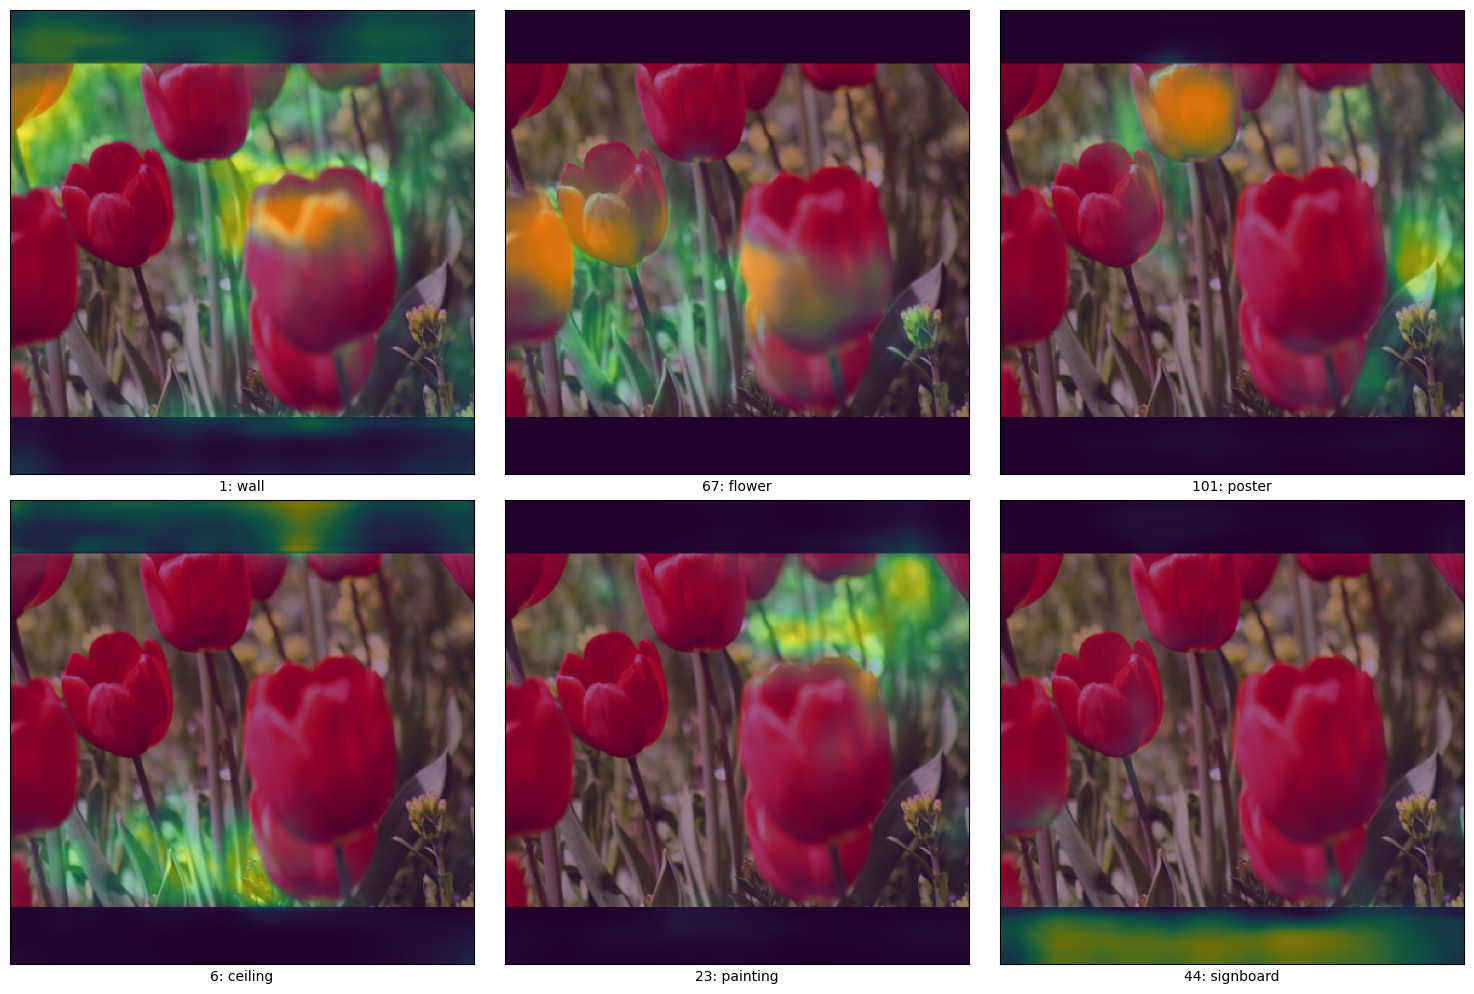

In [22]:
# Overlay the strongest masks on the image.
plt.figure(figsize=(15, 10))
for position, index in enumerate(top_mask_indices):
    plt.subplot(2, 3, position + 1)
    plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.imshow(np.clip(image[0].numpy(), 0, 1))
    plt.imshow(predictions[:, :, index], alpha=0.5)
    plt.xlabel(f"{index}: {segmentation_label(int(index))}")
plt.tight_layout()
plt.show()

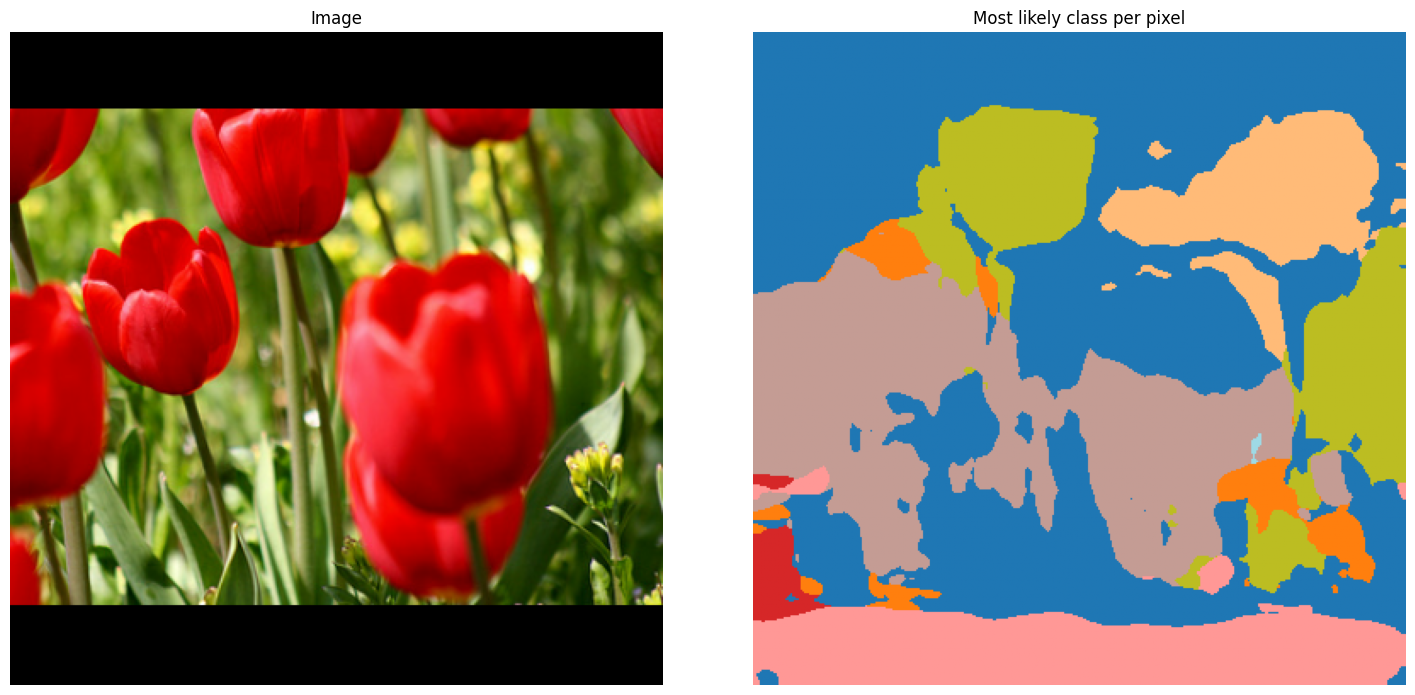

Share of the image by class:
  wall                            31.2 %
  flower                          20.9 %
  poster                          11.6 %
  signboard                       10.9 %
  ceiling                         10.5 %
  painting                         7.1 %
  sky                              3.1 %
  plant                            1.7 %


In [23]:
# CHANGE (new cell): one combined map. Taking argmax over the class axis gives each
# pixel its single most likely class - the segmentation result as normally presented,
# rather than one mask at a time.
combined = predictions.argmax(axis=2)
present, counts = np.unique(combined, return_counts=True)
order = np.argsort(counts)[::-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))
ax1.imshow(np.clip(image[0].numpy(), 0, 1)); ax1.set_title("Image"); ax1.axis("off")
ax2.imshow(combined, cmap="tab20"); ax2.set_title("Most likely class per pixel")
ax2.axis("off")
plt.tight_layout()
plt.show()

total_pixels = combined.size
print("Share of the image by class:")
for position in order[:8]:
    index, count = int(present[position]), int(counts[position])
    print(f"  {segmentation_label(index):<30s} {100 * count / total_pixels:5.1f} %")

### The full mask grid

The original's exhaustive view, kept because seeing how many masks are empty makes the
point that the model scores all 150 classes for every image regardless of what is in it.

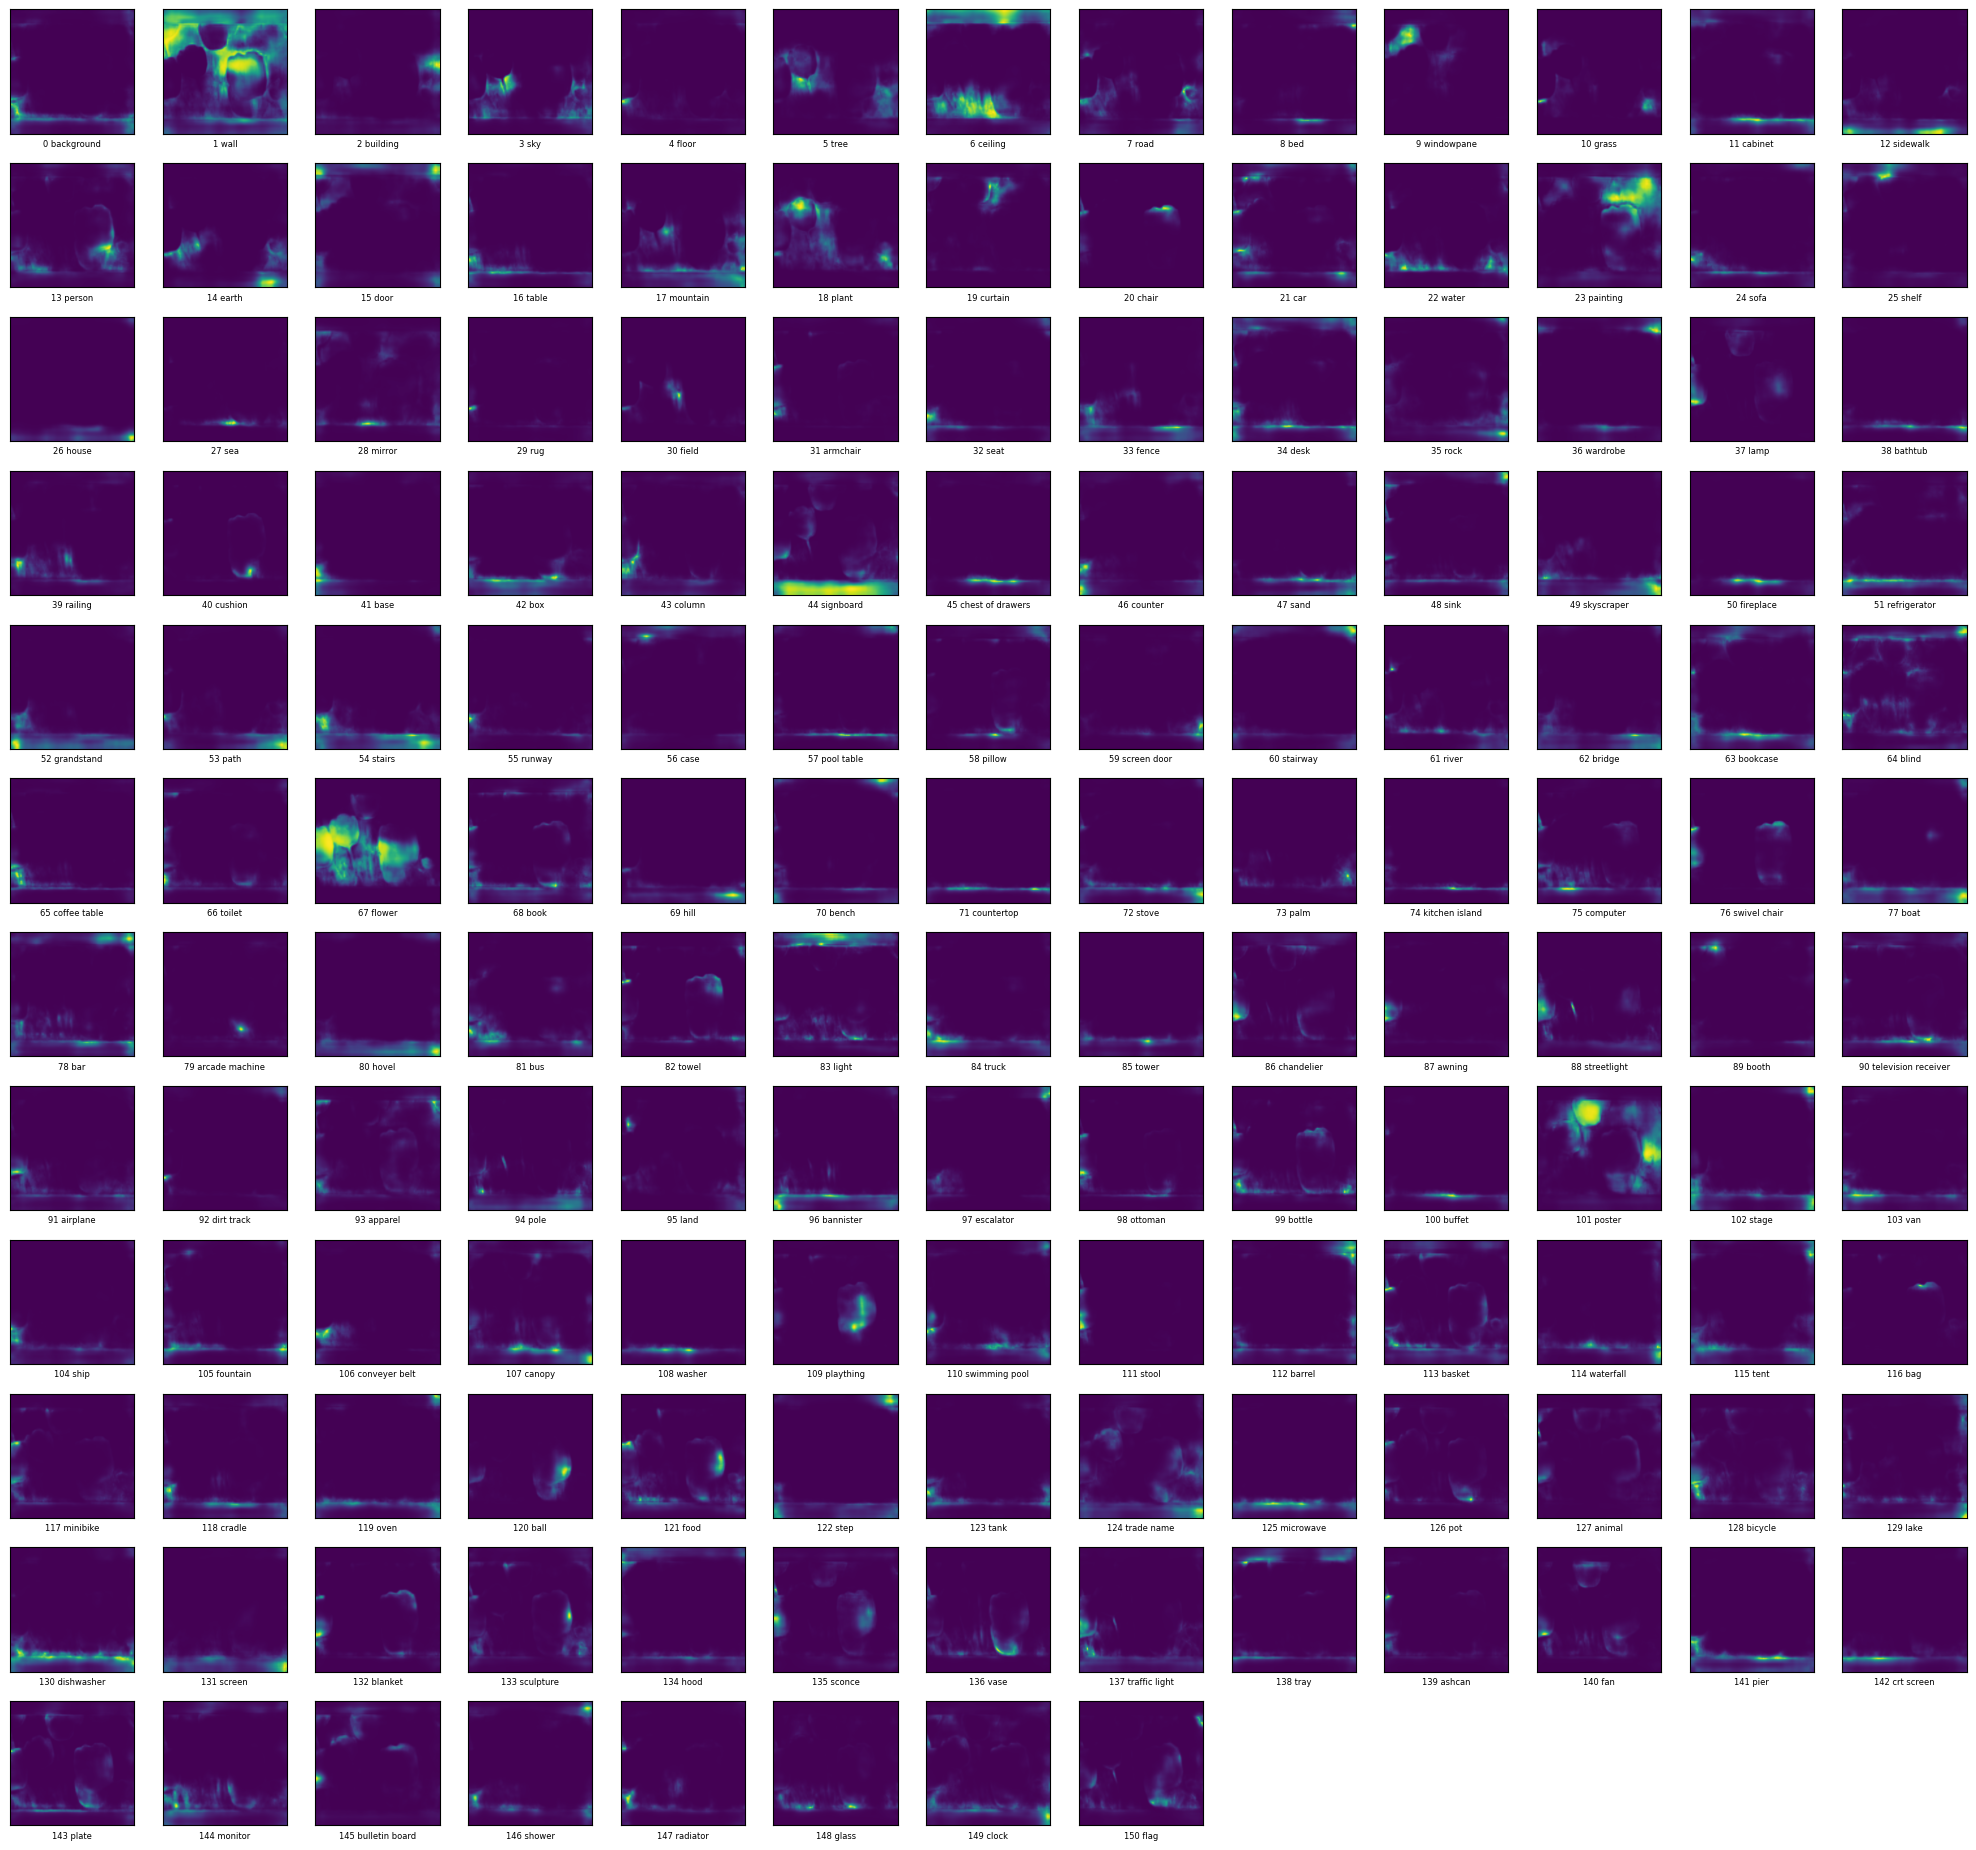

In [24]:
plot_dim = math.ceil(math.sqrt(number_of_masks))

plt.figure(figsize=(20, 20))
for i in range(number_of_masks):
    plt.subplot(plot_dim, plot_dim, i + 1)
    plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.imshow(predictions[:, :, i])
    plt.xlabel(f"{i} {segmentation_label(i)}", fontsize=6)
plt.tight_layout()
plt.show()

---
# Summary

## The three tasks, side by side

| | Classification | Detection | Segmentation |
|---|---|---|---|
| Output | one label for the image | box + label + score per object | a class for every pixel |
| Model here | EfficientNetV2-S | SSD MobileNet V2 | HRNet-W48 |
| Trained on | ImageNet-21k / 1k | Open Images V4 (600) | ADE20k (150) |
| Cost | cheapest | moderate | most expensive |
| Fails when | several subjects share the frame | objects are small or overlap | boundaries are ambiguous |

The crop experiment in Chapter 1 shows why the three exist: classification is forced to
choose a single answer, so its answer depends on the framing. Detection removes that
constraint by reporting several objects with positions. Segmentation removes the box as
well and labels the pixels themselves. Each step costs more computation and more detailed
training labels.

## Defects found in the original

| # | Defect | Effect |
|---|---|---|
| 1 | `preprocess_image` reads `image.shape[2]` on a possibly 2-D array | crashes on any grayscale image |
| 2 | The grayscale guard sits in `load_image`, after `preprocess_image` has already run | unreachable; would also produce a 5-D tensor if it ever fired |
| 3 | No RGBA handling | PNGs and screenshots arrive with 4 channels |
| 4 | No EXIF rotation | phone photos load sideways |
| 5 | `download_and_resize_image` calls `tempfile.mkstemp()` and `urlopen()`, neither imported | `NameError` if called; never called, so it sits as dead code |
| 6 | `load_img()` defined, never used | dead code |
| 7 | `if tf.reduce_max(img) > 1.0: img = img / 255.` after `convert_image_dtype` | can never fire - the conversion already produced `[0, 1]` |
| 8 | Segmentation overlay uses hard-coded mask indices `[2, 5, 13, 18]` | meaningless for any other image |
| 9 | Inline comment says `output_classes=202` while 151 labels are loaded | the loop reads the true count from the tensor so nothing breaks, but the comment is misleading |
| 10 | Crop sliders are not clamped to the image | a far-right or far-bottom crop yields an empty slice and a confusing failure inside the model |

Defects 1-4 all have the same cause: the loader was written against fifteen known-good
RGB JPEGs. They only surface once the notebook is pointed at arbitrary images, which is
what this assignment asks for.

## Limitations

- Nothing here is trained or evaluated, so there are no accuracy figures - only
  qualitative output on whatever image is supplied. Judging these models properly would
  need a labelled test set.
- All three models carry their training sets' biases. ADE20k is scene-centric, so indoor
  and outdoor scenes segment far better than close-ups. Open Images covers 600 object
  classes and finds nothing outside them.
- SSD MobileNet V2 is the small, fast detector. The Faster R-CNN model mentioned in the
  original's comments is more accurate on small objects but needs considerably more memory.
- Softmax probabilities are not calibrated confidence. A 0.9 score does not mean the model
  is right 90 % of the time, particularly on images unlike its training data.